Dataset saved successfully!
Dataset shape: (10000, 15)
Rows shared by train and test: 0
Train: (8000, 14) Test: (2000, 14)
Encoded features: 51
Missing values left: 0
Best parameters: {'ccp_alpha': 0, 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 50}
Best CV PR AUC: 0.754
[[1591  243]
 [  10  156]]
              precision    recall  f1-score   support

           0      0.994     0.868     0.926      1834
           1      0.391     0.940     0.552       166

    accuracy                          0.874      2000
   macro avg      0.692     0.904     0.739      2000
weighted avg      0.944     0.874     0.895      2000

ROC AUC: 0.966 | PR AUC: 0.761
Baseline PR AUC (fraud rate): 0.083

Tree importances:
Service_Claim_days         0.9062
Claim_Amount               0.0652
No_of_Claims_Provider      0.0168
Length_of_Stay             0.0038
Diagnosis_Code_F41.9       0.0029
Patient_Age                0.0026
Diagnosis_Code_E11.9       0.0019
State_FL                   0.0007
I

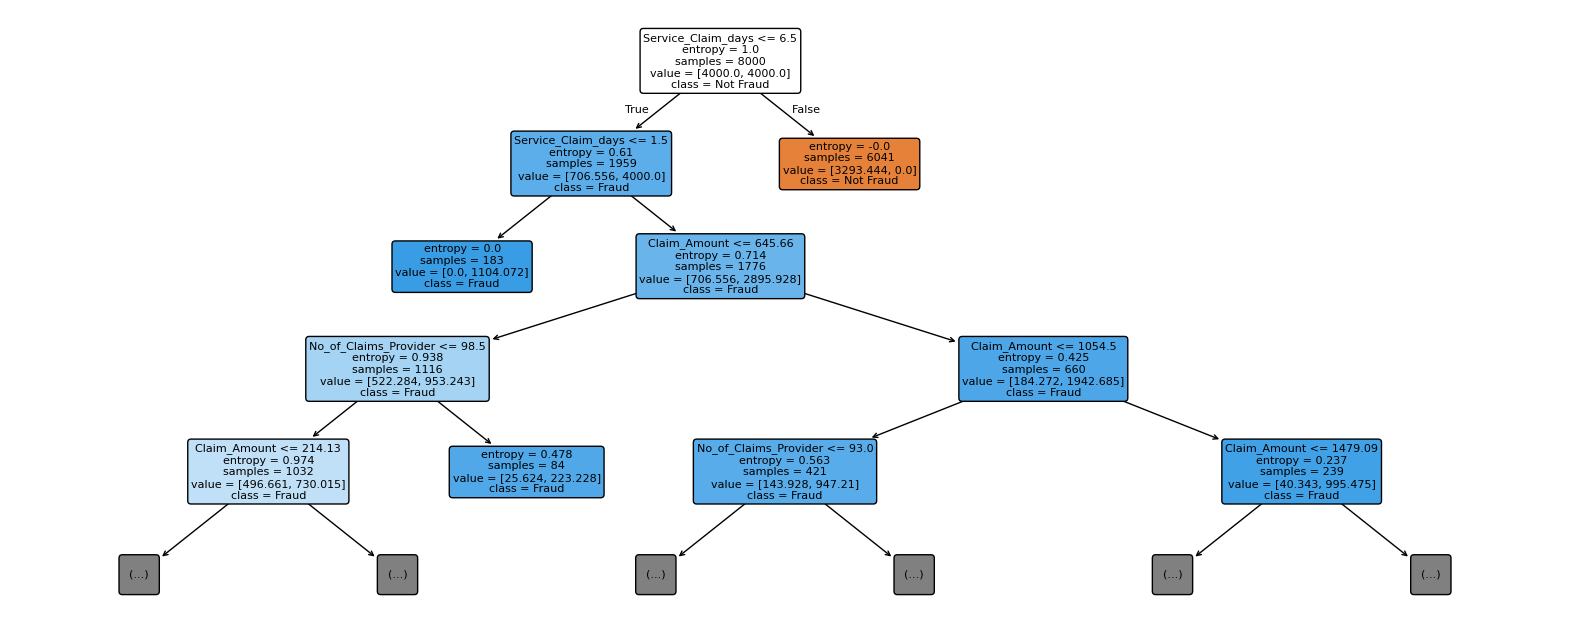

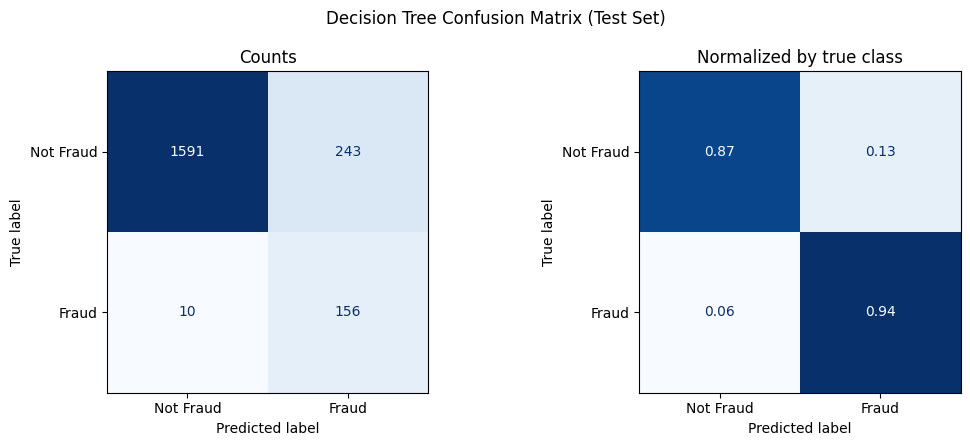

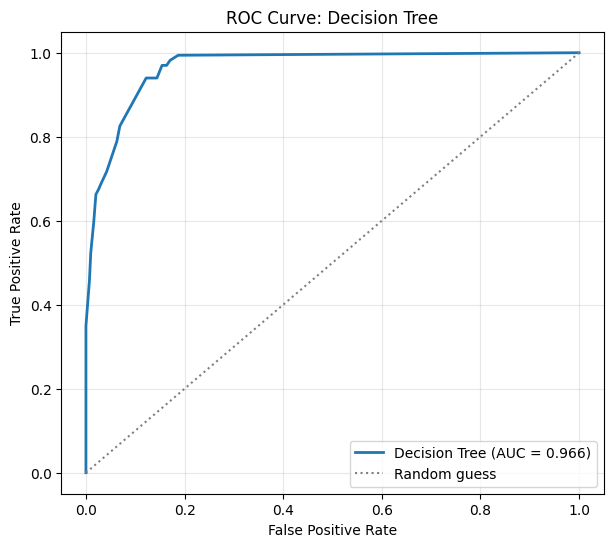

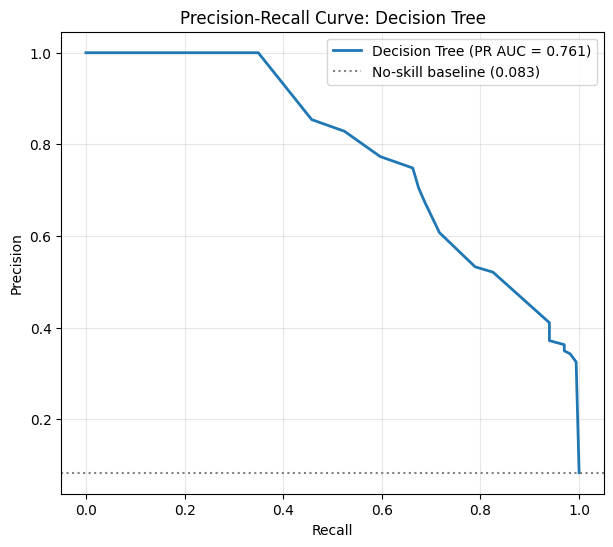

In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay)
import matplotlib.pyplot as plt


df = pd.read_csv('health_data.csv')

target = 'Is_Fraud'
numeric_cols = ['Claim_Amount', 'Patient_Age', 'No_of_Claims_Provider', 'Service_Claim_days',
                'Length_of_Stay', 'Prior_Visits_12m', 'Chronic_Condition_Flag']
categorical_cols = ['Insurance_Type', 'Patient_Gender', 'Provider_Specialty', 'Visit_Type',
                    'State', 'Diagnosis_Code', 'Procedure_Code']

X_raw = df[numeric_cols + categorical_cols].copy()
y = df[target]

analysis_data = X_raw.copy()
analysis_data[target] = y

analysis_data.to_csv('dt_prepared_data.csv', index=False)

print("Dataset saved successfully!")
print("Dataset shape:", analysis_data.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_test = X_train.copy(), X_test.copy()
print("Rows shared by train and test:", len(set(X_train.index) & set(X_test.index)))  # must be 0
print("Train:", X_train.shape, "Test:", X_test.shape)


for d in (X_train, X_test):
    d['Provider_Specialty'] = d['Provider_Specialty'].fillna('Unknown')
train_medians = X_train[numeric_cols].median()
X_train[numeric_cols] = X_train[numeric_cols].fillna(train_medians)
X_test[numeric_cols] = X_test[numeric_cols].fillna(train_medians)

for d in (X_train, X_test):
    d[categorical_cols] = d[categorical_cols].astype(str)
X_train_oh = pd.get_dummies(X_train, columns=categorical_cols, dtype=int)
X_test_oh = pd.get_dummies(X_test, columns=categorical_cols, dtype=int).reindex(
    columns=X_train_oh.columns, fill_value=0)
print("Encoded features:", X_train_oh.shape[1])
print("Missing values left:", int(X_train_oh.isna().sum().sum() + X_test_oh.isna().sum().sum()))  # must be 0

param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 4, 5, 6, 8],
    'min_samples_leaf': [20, 50, 100],
    'ccp_alpha': [0, 0.0005, 0.001],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(DecisionTreeClassifier(class_weight='balanced', random_state=42),
                    param_grid, cv=cv, scoring='average_precision', n_jobs=-1)
grid.fit(X_train_oh, y_train)
model = grid.best_estimator_
print("Best parameters:", grid.best_params_)
print("Best CV PR AUC:", round(grid.best_score_, 3))


y_pred = model.predict(X_test_oh)
y_prob = model.predict_proba(X_test_oh)[:, 1]
roc = roc_auc_score(y_test, y_prob)
pr = average_precision_score(y_test, y_prob)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, digits=3))
print("ROC AUC:", round(roc, 3), "| PR AUC:", round(pr, 3))
print("Baseline PR AUC (fraud rate):", round(y_test.mean(), 3))


importances = pd.Series(model.feature_importances_, index=X_train_oh.columns).sort_values(ascending=False)
print("\nTree importances:")
print(importances.head(10).round(4))

perm = permutation_importance(model, X_test_oh, y_test, scoring='average_precision',
                              n_repeats=10, random_state=42, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_train_oh.columns).sort_values(ascending=False)
print("\nPermutation importances (drop in test PR AUC):")
print(perm_imp.head(10).round(4))


plt.figure(figsize=(20, 8))
plot_tree(model, feature_names=X_train_oh.columns, class_names=['Not Fraud', 'Fraud'],
          filled=True, rounded=True, fontsize=8, max_depth=4)
plt.savefig('decision_tree.png', dpi=300, bbox_inches='tight')
plt.show()

"""Confusion Matrix"""

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Not Fraud', 'Fraud'],
                                        cmap='Blues', values_format='d', ax=axes[0], colorbar=False)
axes[0].set_title('Counts')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Not Fraud', 'Fraud'],
                                        normalize='true', cmap='Blues', values_format='.2f',
                                        ax=axes[1], colorbar=False)
axes[1].set_title('Normalized by true class')
plt.suptitle('Decision Tree Confusion Matrix (Test Set)')
plt.tight_layout()
plt.savefig('dt_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

""" Plotting the ROC Curve"""
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, lw=2, label=f'Decision Tree (AUC = {roc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle=':', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Decision Tree')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.savefig('dt_roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()

"""Precision recall curve"""
prec, rec, _ = precision_recall_curve(y_test, y_prob)
plt.figure(figsize=(7, 6))
plt.plot(rec, prec, lw=2, label=f'Decision Tree (PR AUC = {pr:.3f})')
plt.axhline(y_test.mean(), color='gray', linestyle=':', label=f'No-skill baseline ({y_test.mean():.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve: Decision Tree')
plt.legend(loc='upper right')
plt.grid(alpha=0.3)
plt.savefig('dt_pr_curve.png', dpi=300, bbox_inches='tight')
plt.show()